# Explainable Intrusion Detection using Counterfactuals

### Munashe Madziwanyika

This notebook contains all the code and experiments that were carried out for the Honours thesis.

# Imports

In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split, StratifiedGroupKFold
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, precision_score, recall_score, accuracy_score,
    balanced_accuracy_score, classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns
import seaborn as sns
import copy
from dataclasses import dataclass, asdict

In [3]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'

Could adding a layer improve performance?

### Random Seed
42 is the answer to life

# Loading Data

**Note** Dropping the 'Unnamed: 0' column reduced binary accuracy from 99.96% to 96.97%

Dataset might be sorted by label

In [4]:
# df = pd.read_csv('/kaggle/input/datasets/munashemadziwanyika/unr-idd-processed/unr-processed.csv')
# df = pd.read_csv('/kaggle/input/datasets/munashemadziwanyika/unr-idd-multi/unr-multi-processed.csv')
#df = pd.read_csv('/kaggle/input/datasets/munashemadziwanyika/unr-proc/unr-proc.csv')
df = pd.read_csv('unr-proc.csv')
# These cause data leak: Pushing metrics to 100%
# Packets Looked Up and Packets Matched have clear separable ranges
# Sent Packets has very little overlap
# df = df.drop(columns=['Unnamed: 0', 'Sent Packets', 'Sent Bytes', 'Packets Looked Up', 'Packets Matched','Label'])
# df = df.drop(columns=['Unnamed: 0', 'Sent Packets', 'Sent Bytes', 'Packets Looked Up', 'Packets Matched','Binary Label'])
df = df.drop(columns=['Unnamed: 0', 'Binary Label'])
# df = df.drop(columns=['Binary Label'])
df.head()

,Switch ID,Port Number,Received Packets,Received Bytes,Sent Bytes,Sent Packets,Port alive Duration (S),Delta Received Packets,Delta Received Bytes,Delta Sent Bytes,...,Connection Point,Total Load/Rate,Total Load/Latest,Unknown Load/Rate,Unknown Load/Latest,Latest bytes counter,Active Flow Entries,Packets Looked Up,Packets Matched,Label
0,of:000000000000000c,Port#:1,132,9181,6311853,238,46,0,0,280,...,1,0,0,0,0,0,9,767,688,1
1,of:000000000000000c,Port#:2,187,6304498,15713,171,46,146,5908166,5969,...,2,0,0,0,0,0,9,767,688,1
2,of:000000000000000c,Port#:3,235,6311567,8030,58,46,2,278,280,...,3,0,0,0,0,0,9,767,688,1
3,of:000000000000000c,Port#:4,59,7878,16439,182,46,2,278,280,...,4,0,0,0,0,0,9,767,688,1
4,of:000000000000000a,Port#:1,188,6304547,16497,183,46,0,0,280,...,1,0,0,0,0,0,7,489,403,1


In [5]:
# df['Label'].value_counts()

In [ ]:
groups = (df['Switch ID'].astype(str) + '_' + df['Port Number'].astype(str)).values

X = df.drop(columns=['Switch ID', 'Port Number', 'Connection Point', 'Label'])
y = df['Label']

In [7]:
X = X.values
y = y.values

### Grouped Split

In [8]:
def group_split(X, y, groups, n_splits=5, seed=42):
    kfold = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    kept_idx, held_idx = next(kfold.split(X,y, groups))
    return kept_idx, held_idx

train_val_idx, test_idx = group_split(X, y, groups, n_splits=4)

train_start, val_start = group_split(X[train_val_idx], y[train_val_idx], groups[train_val_idx], n_splits=4)
train_idx, val_idx = train_val_idx[train_start], train_val_idx[val_start]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

### Extract Normal features

In [9]:
X_normal = X_train[y_train == 0]
# X_normal = X_normal.drop(columns=['Switch ID', 'Port Number', 'Connection Point'])
# X_normal = X_normal.drop('Label', axis=1)
q_low, q_high = np.quantile(X_normal, [0.01, 0.99], axis=0)

### Scale X

In [10]:
scaler = StandardScaler()

Overflow covers a small percentage of attacks so using stratify avoids omitting it from the testing data

In [12]:
def to_data_loader(X, y, batch_size=32, shuffle=False):
    X_t = torch.FloatTensor(X)
    y_t = torch.LongTensor(y)
    return DataLoader(TensorDataset(X_t, y_t), batch_size=batch_size, shuffle=shuffle)

### Random Split

In [13]:
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Making a validation set from the training set
# X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.2, random_state=42, stratify=y_train)

Adding SMOTE to see if that improves performance on Overflow

In [14]:
from imblearn.over_sampling import SMOTE

In [15]:
smote = SMOTE(sampling_strategy='not majority', random_state=42)
X_train_sm, y_train_sm = smote.fit_resample(X_train, y_train)

In [16]:
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

# batch_size = 32

train_dataloader = to_data_loader(X_train_scaled, y_train, shuffle=True)
val_dataloader = to_data_loader(X_val_scaled, y_val)
test_dataloader = to_data_loader(X_test_scaled, y_test)

# X_train = scaler.fit_transform(X_train_sm)
# X_test = scaler.transform(X_test)

### Checking to see that all labels are in the 3 sets

In [17]:
assert not (set(groups[train_idx]) & set(groups[test_idx]))
assert not (set(groups[train_idx]) & set(groups[val_idx]))

for name, yy in [('train', y_train), ('val', y_val), ('test', y_test)]:
    print(name, np.bincount(yy) / len(yy))

train [0.10239336 0.24189346 0.223895   0.15180467 0.02668404 0.25332947]
val [0.10161197 0.24222798 0.22740357 0.16047784 0.0164076  0.25187104]
test [0.09703255 0.24489167 0.22589588 0.13902865 0.03645138 0.25669987]


In [18]:
X_train_tn = torch.FloatTensor(X_train_scaled).to(device)
X_test_tn = torch.FloatTensor(X_test_scaled).to(device)

# Making The Model

## Model Architecture

In [19]:
class IDS_Classifier(nn.Module):
    # def __init__(self, inputs=15, h1=128, h2=64, h3=32, h4=16, outputs=2):
    def __init__(self, inputs=19, h1=128, h2=64, h3=32, h4=16, outputs=6):
    # def __init__(self, inputs=19, h1=256, h2=128, h3=64, h4=32, h5=16, outputs=6):
    # def __init__(self, inputs=19, h1=32, h2=32, h3=32, h4=32, outputs=6):
    # def __init__(self, inputs=19, h1=128, h2=128, h3=128, h4=128, h5=256, outputs=6): 
        super().__init__()
        # self.dropout = nn.Dropout(0.2)
        self.fc1 = nn.Linear(inputs, h1)
        # self.dropout = nn.Dropout(0.2)
        self.fc2 = nn.Linear(h1, h2)
        # self.bn1 = nn.BatchNorm1d(h2)
        # self.dropout = nn.Dropout(0.2)
        self.fc3 = nn.Linear(h2, h3)
        # self.bn2 = nn.BatchNorm1d(h3)
        self.dropout = nn.Dropout(0.2)
        self.fc4 = nn.Linear(h3, h4)
        # self.bn3 = nn.BatchNorm1d(h4)
        # self.fc5 = nn.Linear(h4, h5)
        self.out = nn.Linear(h4, outputs)
        # self.out = nn.Linear(h5, outputs)

    def forward(self, x):
        # x = self.dropout(x)
        x = F.relu(self.fc1(x))
        # x = self.dropout(x)
        x = F.relu(self.fc2(x))
        # x = self.bn1(x)
        # x = self.dropout(x)
        x = F.relu(self.fc3(x))
        # x = self.bn2(x)
        x = self.dropout(x)
        x = F.relu(self.fc4(x))
        # x = self.bn3(x)
        # x = F.relu(self.fc5(x))
        x = self.out(x)
        return x

In [20]:
torch.manual_seed(42)
# create an instance of model
in_features = X_train.shape[1]
model = IDS_Classifier(inputs=in_features).to(device)

# Model Experimentation

## Early Stopping

In [21]:
class EarlyStopping:
    def __init__(self, patience=5, delta=0):
        self.patience = patience
        self.delta = delta
        self.best_score = None
        self.early_stop = False
        self.counter = 0
        self.best_model_state = None

    def __call__(self, val_loss, model):
        score = -val_loss
        if self.best_score is None:
            self.best_score = score
            self.best_model_state = copy.deepcopy(model.state_dict())
        elif score < self.best_score + self.delta:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        else:
            self.best_score = score
            self.best_model_state = copy.deepcopy(model.state_dict())
            self.counter = 0

    def load_best_model(self, model):
        model.load_state_dict(self.best_model_state)

## Training Epoch

In [22]:
def train(train_dataloader, val_dataloader, model, criterion, optimiser, early_stopping, cnt, t_losses=[], t_accs=[], v_losses=[], v_accs=[]):
    train_acc = train_loss = train_n = train_correct = 0
    model.train()
    for batch, (X, y) in enumerate(train_dataloader):
        X, y = X.to(device), y.to(device)
        pred = model(X)
        loss = criterion(pred, y)
        loss.backward()
        optimiser.step()
        optimiser.zero_grad()
        batch_size = y.size(0)
        train_loss += loss.item() * batch_size
        train_correct += (pred.argmax(1) == y).sum().item()
        train_n += batch_size

    val_acc = val_loss = val_n = val_correct = 0
    v_true, v_pred = [], []
    model.eval()
    with torch.no_grad():
        for batch, (X, y) in enumerate(val_dataloader):
            X, y = X.to(device), y.to(device)
            pred = model(X)
            loss = criterion(pred, y)
            batch_size = y.size(0)
            val_loss += loss.item() * batch_size
            val_correct += (pred.argmax(1) == y).sum().item()
            val_n += batch_size
            v_true.append(y.cpu())
            v_pred.append(pred.argmax(1).cpu())

    train_loss = train_loss / train_n
    train_acc = train_correct / train_n
    val_loss = val_loss / val_n
    val_acc = val_correct / val_n

    t_losses.append(train_loss)
    t_accs.append(train_acc)
    v_losses.append(val_loss)
    v_accs.append(val_acc)

    val_f1 = f1_score(torch.cat(v_true).numpy(), torch.cat(v_pred).numpy(), average='macro')
    early_stopping(1 - val_f1, model)
    # early_stopping(val_loss, model)

    if cnt % 10 == 0:
        print(f'Train loss: {train_loss:.5f}, Val loss: {val_loss:.5f} | Train acc: {train_acc:.5f}, Val acc: {val_acc:.5}')

## Testing

In [23]:
def test(dataloader, model, criterion, y_true=[], y_pred=[]):
    size = len(dataloader.dataset)
    num_batches = len(dataloader)
    model.eval()
    test_loss = correct = 0
    n = 0
    preds, targets = [], []
    with torch.no_grad():
        for X, y in dataloader:
            X, y = X.to(device), y.to(device)
            pred = model(X)
            batch_size = y.size(0)
            test_loss += criterion(pred, y).item() * batch_size
            preds.append(pred.argmax(1).cpu())
            targets.append(y.cpu())
            correct += (pred.argmax(1) == y).type(torch.float).sum().item()
            n += batch_size
    # test_loss /= num_batches
    test_loss /= n
    correct /= size
    y_pred = torch.cat(preds).numpy()
    y_true = torch.cat(targets).numpy()
    print(f'Test Error: \n Accuracy: {(100*correct):.5}%, Avg loss: {test_loss:.5f}\n')
    return y_true, y_pred

In [24]:
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight('balanced', classes=np.unique(y_train), y=y_train)
class_weights = class_weights ** 0.5
cw = torch.FloatTensor(class_weights).to(device)

In [25]:
y_train_tn = torch.LongTensor(y_train).to(device)
# y_train = torch.LongTensor(y_train_sm).to(device)
y_test_tn = torch.LongTensor(y_test).to(device)

Adding class weights (9.0, 1.0) to see if it improves minority recall: currently 73% with 94% precision.<br>
Recall increased to 98% but precision decreased to 67%

Changing weights to (7.0, 1.0) to see if there is an improvement: recall still as 97% and precision increased to 69%

Consider using the ratio attack:normal ratio for the weight

Using class weights to see if it will improve the recall for Overflow

In [26]:
# Set the error criterion
# criterion = nn.CrossEntropyLoss(weight=torch.FloatTensor([7.0, 1.0]).to(device))
criterion = nn.CrossEntropyLoss(weight=cw)
# criterion = nn.CrossEntropyLoss(weight=torch.FloatTensor(class_weights).to(device))

# Use Adam opitmizer
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)

## Training The Model

**For Binary:** Increasing epochs from 50 to 100 slightly improved normal precision from 69% to 71%

In [27]:
early_stopping = EarlyStopping(patience=10, delta=1e-3)

In [28]:
epochs = 100
t_loss, t_acc, v_loss, v_acc = [], [], [], []

for epoch in range(epochs):
    if epoch % 10 == 0:
        print(f'Epoch {epoch} {"-"*70}')
    train(train_dataloader, val_dataloader, model, criterion, optimizer, early_stopping, epoch, t_losses=t_loss, t_accs=t_acc, v_losses=v_loss, v_accs=v_acc)
    if early_stopping.early_stop:
        print(f'Early stopping at epoch {epoch+1}')
        break
print('Done training')
early_stopping.load_best_model(model)

Epoch 0 ----------------------------------------------------------------------
Train loss: 0.88235, Val loss: 0.62623 | Train acc: 0.63540, Val acc: 0.73446
Epoch 10 ----------------------------------------------------------------------
Train loss: 0.53377, Val loss: 1.63042 | Train acc: 0.77934, Val acc: 0.75518
Epoch 20 ----------------------------------------------------------------------
Train loss: 0.48901, Val loss: 1.83089 | Train acc: 0.80173, Val acc: 0.74424
Early stopping at epoch 25
Done training


## Visualising the training process

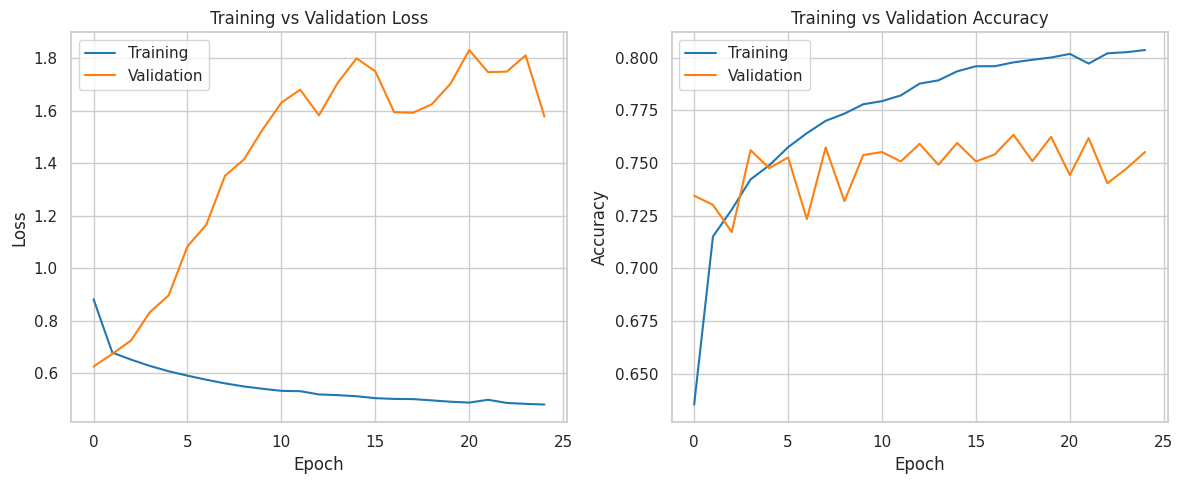

In [29]:
sns.set_theme(style='whitegrid')
epochs = range(0, len(v_loss))
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
sns.lineplot(x=epochs, y=t_loss, color='tab:blue', label='Training', ax=ax[0])
sns.lineplot(x=epochs, y=v_loss, color='tab:orange', label='Validation', ax=ax[0])
ax[0].set(xlabel='Epoch', ylabel='Loss', title='Training vs Validation Loss')

sns.lineplot(x=epochs, y=t_acc, color='tab:blue', label='Training', ax=ax[1])
sns.lineplot(x=epochs, y=v_acc, color='tab:orange', label='Validation', ax=ax[1])
ax[1].set(xlabel='Epoch', ylabel='Accuracy', title='Training vs Validation Accuracy')
fig.tight_layout()
plt.show()

### Regularisation

Batch normalisation down to 84.659% (Early stopped at epoch 36)

Drop out on input layer down to 72.738% (Early stopped at epoch 44)

Drop out after each hidden layer up to 83.549% (No early stop before 100 epochs)

Batch size 32 -> 64 (lr 1e-3) down to 83.803% (Early stopped at 43)

Patience 10 - 15, Batch size 32, lr 1e-3 up to 85.367% (Early stopped at 77)

Drop out only after 3rd layer down to 84.218% (Early stopped at 65) [Losses resemble each other more but signs of overfitting]

## Evaluate The Model

In [30]:
y_true, y_pred = test(test_dataloader, model, criterion)
print(len(y_true), len(y_pred))

accuracy = accuracy_score(
    y_true,
    y_pred

)

bal_accuracy = balanced_accuracy_score(
    y_true,
    y_pred
)

precision = precision_score(
    y_true,
    y_pred,
    average='macro'
)

recall = recall_score(
    y_true,
    y_pred,
    average='macro'
)

f1score = f1_score(
    y_true,
    y_pred,
    average='macro'
)

print(f'Accuracy: {accuracy*100:.5f}%')
print(f'Balanced Accuracy: {bal_accuracy*100:.5f}%')
print(f'Precision: {precision*100:.5f}%')
print(f'Recall: {recall*100:.5f}%')
print(f'F1 Score: {f1score*100:.5f}%')

Test Error: 
 Accuracy: 76.938%, Avg loss: 0.54907

9739 9739
Accuracy: 76.93808%
Balanced Accuracy: 71.70203%
Precision: 75.85271%
Recall: 71.70203%
F1 Score: 72.80361%


**Note**:

F1 score increases from 74.99 to 79.17% when SMOTE is not used. Overflow's proximity to other classes may make SMOTE cause performance to decrease due to other synthetic data points looking too much like other attack types like Blackhole, TCP-SYN, and PortScan. Recall for Overflow is significantly lower now.

Prec, Rec, and F1 for Overflow (The problematic class) changed from **0.71, 0.34, 0.46**  to  **0.78, 0.32, 0.46** with 3 layers.

<Axes: >

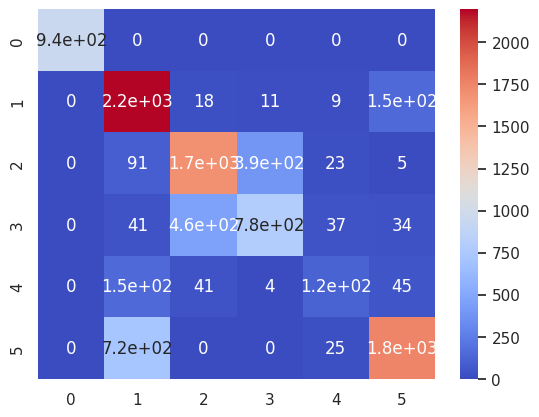

In [31]:
c_mat = confusion_matrix(y_true, y_pred)
sns.heatmap(c_mat, annot=True, cmap='coolwarm')

### Class weights
Class weighting doesn't help

| Metric | Unweighted | Full (6×) | Sqrt (2.4×) |
|---|---|---|---|
| Class 4 recall | 37% | 73% | 42% |
| Class 4 precision | 74% | 21% | 55% |
| Class 4 F1 | 49% | 33% | 48% |
| Macro F1 | ~81% | ~76% | ~80% |
| Accuracy | 84% | 80% | 84% |

Add figures from classification report

In [32]:
x_raw = [1310, 37839123, 12822532, 2250, 1857, 0, 0, 280, 2, 5, 0, 0, 0, 0, 0, 4, 4814, 4734]
x_scaled = scaler.transform([x_raw])
x_scaled = torch.FloatTensor(x_scaled).to(device)
x = torch.FloatTensor(x_raw).to(device)
pred = model(x_scaled)
probs = torch.softmax(pred, dim=1)
print(probs.argmax(dim=1).item())

2


In [34]:
# report = classification_report(y_test.cpu(), y_pred.cpu(), target_names=['Normal', 'Attack'])
labels = [0, 1, 2, 3, 4, 5]
report = classification_report(y_true, y_pred, labels=labels, target_names=['Normal', 'TCP-SYN', 'Blackhole', 'Diversion', 'Overflow', 'PortScan'])
print(report)

              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       945
     TCP-SYN       0.69      0.92      0.79      2385
   Blackhole       0.77      0.77      0.77      2200
   Diversion       0.66      0.58      0.62      1354
    Overflow       0.55      0.33      0.41       355
    PortScan       0.88      0.70      0.78      2500

    accuracy                           0.77      9739
   macro avg       0.76      0.72      0.73      9739
weighted avg       0.78      0.77      0.77      9739



**To-Do (For Binary)** Maybe apply SMOTE to improve Normal recall

Currently 0.73

In [35]:
print(pd.Series(y_test).value_counts().sort_index())

0     945
1    2385
2    2200
3    1354
4     355
5    2500
Name: count, dtype: int64


## Save The Model

In [36]:
torch.save(model.state_dict(), 'unr_classifier.pt')

## Random Forest

Fitting a Random Forest model on random split with connection point and on the grouped data

Random Forest:
  Random Split
    Accuracy: 94.02330802950925%
    Macro F1: 93.156010079853%
  Grouped Split:
    Accuracy: 84.08460827600369%
    Macro F1: 82.54338112341547%


<Axes: >

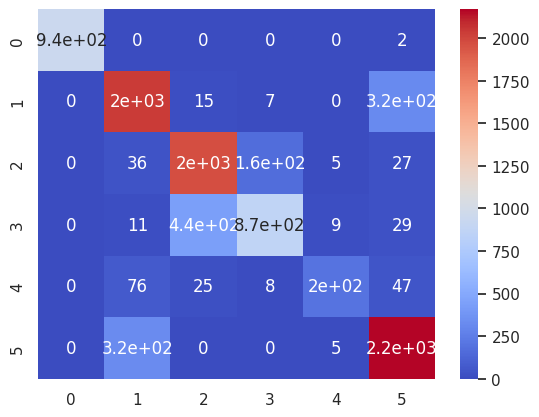

In [37]:
from sklearn.ensemble import RandomForestClassifier

# Random Split
X_train_rf, X_test_rf, y_train_rf, y_test_rf = train_test_split(df.drop(columns=['Switch ID', 'Port Number', 'Label']), df['Label'], stratify=y, random_state=42)
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_rf, y_train_rf)

y_rf = rf.predict(X_test_rf)

macrof1_rf = f1_score(y_test_rf, y_rf, average='macro')
acc_rf = accuracy_score(y_test_rf, y_rf)

print("Random Forest:")
print("  Random Split")
print(f"    Accuracy: {acc_rf * 100}%")
print(f"    Macro F1: {macrof1_rf * 100}%")

# Grouped Split
X_lst = []
y_lst = []

for batch_X, batch_y in train_dataloader:
    X_lst.append(batch_X.numpy())
    y_lst.append(batch_y.numpy())

X_train_rf = np.vstack(X_lst)
y_train_rf = np.concatenate(y_lst)

X_lst = []
y_lst = []

for batch_X, batch_y in test_dataloader:
    X_lst.append(batch_X.numpy())
    y_lst.append(batch_y.numpy())

X_test_rf = np.vstack(X_lst)
y_test_rf = np.concatenate(y_lst)

rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train_rf, y_train_rf)

y_rf = rf.predict(X_test_rf)

macrof1_rf = f1_score(y_test_rf, y_rf, average='macro')
acc_rf = accuracy_score(y_test_rf, y_rf)

print("  Grouped Split:")
print(f"    Accuracy: {acc_rf * 100}%")
print(f"    Macro F1: {macrof1_rf * 100}%")

cm = confusion_matrix(y_test_rf, y_rf)
sns.heatmap(cm, annot=True, cmap='coolwarm')

# Making the Explainer

## Defining the MAD

Adding this modification to the distance function ensures that features with extreeme values do not disproportionately affect the distance function. Features with much larger ranges do not dominate the calculation. (Used by Wachter et al, 2017)

In [38]:
def median_absolute_deviation(X):
    median = np.median(X, axis=0)
    # Since we're dividing by MAD, there must be no 0 variances
    mad = np.median(np.abs(X - median), axis=0)
    mad[mad == 0] = 1.0
    return mad

## Defining Counterfactual Search

Applying constraints directly doesn't seem to be working

In [39]:
@dataclass
class CFResult:
    cf: np.ndarray
    success: bool
    orig_class: int
    target_class: int
    confidence: float
    num_changes: int
    attempts: int
    total_steps: int
    lam: float = None

In [ ]:
# This was rejected as the main constraint method because of low validity
def apply_constraints(x_cf, x_orig, immutable):
    x_cf = torch.clamp(x_cf, min=0)
    low_tensor = torch.FloatTensor(q_low).to(device)
    high_tensor = torch.FloatTensor(q_high).to(device)
    # x_cf = torch.clamp(x_cf, low_tensor, high_tensor)
    dur, d_dur = x_cf[4], x_cf[9]
    bandwidth = 10e6 / 8
    ip_max = 2**16 - 1

    x_cf[immutable] = x_orig[immutable]

    # bandwidth: bytes <= 10 Mbps * time
    x_cf[1] = torch.clamp(x_cf[1], max=bandwidth * dur)
    x_cf[2] = torch.clamp(x_cf[2], max=bandwidth * dur)
    x_cf[6] = torch.clamp(x_cf[6], max=bandwidth * d_dur)
    x_cf[7] = torch.clamp(x_cf[7], max=bandwidth * d_dur)

    x_cf[0] = torch.clamp(x_cf[0], x_cf[1]/ip_max, x_cf[1]/42) # Received Packets
    x_cf[3] = torch.clamp(x_cf[3], x_cf[2]/ip_max, x_cf[2]/42) # Sent Packets
    
    # Delta features <= corresponding Cumulative features
    # Deltas
    x_cf[5] = torch.min(x_cf[5], x_cf[0]) # delta received packets
    x_cf[6] = torch.min(x_cf[6], x_cf[1]) # delta received bytes
    x_cf[7] = torch.min(x_cf[7], x_cf[2]) # delta sent bytes
    x_cf[8] = torch.min(x_cf[8], x_cf[3]) # delta sent packets

    # Packets looked up = packets sent + packets received
    x_cf[16] = torch.max(x_cf[16], x_cf[0] + x_cf[3])
    
    # packets matched can't be more than packets looked up
    x_cf[17] = torch.min(x_cf[17], x_cf[16])

    # Active Flow Entries
    if x_cf[10] > 0 or x_cf[11] > 0 or x_cf[12] > 0 or x_cf[13] > 0:
        # x_cf[15] = torch.max(x_cf[15], torch.tensor(1.0, device=device))
        x_cf[15] = torch.clamp(x_cf[15], low_tensor[15], high_tensor[15])

    # Immutable features
    x_cf[immutable] = x_orig[immutable]

    return x_cf

In [ ]:
def constraint_penalty(x_cf, x, mad_t, q_low, q_high):
    dur, d_dur = x_cf[4], x_cf[9]
    bandwidth = 10e6 / 8
    ip_max = 2**16 - 1 #RFC-894
    min_pkt = 42
    viol = []

    # Features cannot be negative
    for i in range(x_cf.shape[0]):
        viol.append(F.relu(-x_cf[i]/mad_t[i]))

    # Bandwidth: bytes <= 10 Mbps * duration
    viol.append(F.relu((x_cf[1] - bandwidth * dur)/mad_t[1]))
    viol.append(F.relu((x_cf[2] - bandwidth * dur)/mad_t[2]))
    viol.append(F.relu((x_cf[6] - bandwidth * d_dur)/mad_t[6]))
    viol.append(F.relu((x_cf[7] - bandwidth * d_dur)/mad_t[7]))

    # packet size: bytes / ip_max <= packets <= bytes / 42
    viol.append(F.relu((x_cf[1] - ip_max * x_cf[0])/mad_t[1]))
    viol.append(F.relu((min_pkt * x_cf[0] - x_cf[1])/mad_t[1]))
    viol.append(F.relu((x_cf[2] - ip_max * x_cf[3])/mad_t[2]))
    viol.append(F.relu((min_pkt * x_cf[3] - x_cf[2])/mad_t[2]))

    # Delta <= Cumulative
    viol.append(F.relu((x_cf[5] - x_cf[0])/mad_t[5]))
    viol.append(F.relu((x_cf[6] - x_cf[1])/mad_t[6]))
    viol.append(F.relu((x_cf[7] - x_cf[2])/mad_t[7]))
    viol.append(F.relu((x_cf[8] - x_cf[3])/mad_t[8]))

    # Flow table: packets looked up >= sent + received
    #             Packets matched <= looked up
    viol.append(F.relu((x_cf[0] + x_cf[3] - x_cf[16])/mad_t[16]))
    viol.append(F.relu((x_cf[17] - x_cf[16])/mad_t[17]))

    return viol

In [ ]:
def counterfactual(model, x, target, mad, scaler, constrained, threshold, lam=10.0, lr=0.05, steps=1000):
    # Early stopping components
    counter = 0
    best_prox = None
    best_cf = None
    best_pred = None
    patience = 50
    tol=1e-4
    mu = 1.0
    feas = True
    
    model.eval()
    # Indices of immuatable features
    immutable = [4, 9]
    # Indices of integer features
    integers = [0, 1, 2, 3, 4, 5, 6, 7, 8, 15, 16, 17]
    # Making an np version of x
    x_np = x.detach().cpu().numpy()
    x_scaled = scaler.transform(x_np.reshape(1, -1)).flatten()
    x_cf_scaled = torch.FloatTensor(x_scaled).to(device)
    x_cf_scaled = x_cf_scaled.requires_grad_(True)
    x_tensor = torch.FloatTensor(x_np).to(device)
    mad_tensor = torch.FloatTensor(mad).to(device)

    mean = torch.FloatTensor(scaler.mean_).to(device)
    scale = torch.FloatTensor(scaler.scale_).to(device)

    # Creating a scaled version of zero to map to original feature space
    # (This was for projection experiments)
    zero_scaled = (-mean / scale)
    
    optimizer = optim.Adam([x_cf_scaled], lr=lr)

    # Feasibility check
    def feasibility(z):
        return torch.stack(constraint_penalty(z, x_tensor, mad_tensor, q_low, q_high)).max() <= tol

    # Distance function
    def mad_dist(z):
        return torch.mean(torch.abs(z - x_tensor) / mad_tensor)

    # Apply constraints by projection
    def constrain_cf(x_scaled):
        z = (x_scaled * scale + mean).clone()
        z[integers] = torch.round(z[integers]).clamp(min=0)
        z = apply_constraints(z, x_tensor, immutable)
        return z

    # Check if CF has crossed the decision boundary with acceptable confidence
    def query(z):
        probs = torch.softmax(model((z - mean) / scale), dim=0)
        return probs.argmax().item() == target and probs[target].item() >= threshold, probs[target].item()

    # Further revert feature changes that did not affect the model's decision
    def sparsify(z):
        z = z.clone()
        changed = (z != x_tensor).nonzero().flatten().tolist()
        changed.sort(key=lambda i: (abs(z[i] - x_tensor[i]) / mad_tensor[i]).item())
        for i in changed:
            trial = z.clone()
            trial[i] = x_tensor[i]
            if constrained:
                trial = constrain_cf((trial - mean) / scale)
            ok, _ = query(trial)
            if ok and (not constrained or feasibility(trial)):
                z = trial
        return z

    # Search loop
    for step in range(steps):
        optimizer.zero_grad()

        pred = model(x_cf_scaled)
        pred_loss = F.cross_entropy(pred.unsqueeze(0), torch.tensor([target]).to(device))

        # Unscaling for judging constraints against the raw values
        x_cf = x_cf_scaled * scale + mean

        proximity_loss = mad_dist(x_cf)

        # Compute the constraint penalty
        if constrained:
            if (step + 1) % 100 == 0:
                mu = min(mu * 2, 1e4)
            viol = torch.stack(constraint_penalty(x_cf, x_tensor, mad_tensor, q_low, q_high))
            const_pen = mu * (viol**2).sum() if constrained else 0.0
        else:
            const_pen = 0

        loss = pred_loss + lam * proximity_loss + const_pen
        loss.backward()
        # Immutable feature gradients are set to 0
        if constrained:
            x_cf_scaled.grad[immutable] = 0.0

        optimizer.step()

        # Apply constraints for integer features (e.g. counts)
        # and immutable feature values (might be unnecessary)
        with torch.no_grad():
            z = x_cf_scaled * scale + mean
            if constrained:
                z[integers] = torch.round(z[integers])
                z[immutable] = x_tensor[immutable]
                feas = feasibility(z)
            ok, p = query(z)
            dist = mad_dist(z).item()
        # Early stopping check
        if ok and feas:
            if best_cf is None or dist < best_prox:
                best_cf, best_prox, best_pred, counter = z.clone(), dist, p, 0
            else:
                counter += 1
                if counter >= patience:
                    break

    n_steps = step + 1

    # Final check at current lambda:
    #   If a best CF exists, apply sparsification
    #   then do a final feasibility check
    with torch.no_grad():
        if best_cf is None:
            best_cf = x_cf_scaled * scale + mean
            if constrained:
                best_cf[integers] = torch.round(best_cf[integers])
                best_cf[immutable] = x_tensor[immutable]
        else:
            best_cf = sparsify(best_cf) if constrained else best_cf
        ok, conf = query(best_cf)
        success = (ok and (not constrained or feasibility(best_cf))) if constrained else ok

    return best_cf.cpu().numpy(), n_steps, success, conf

In [43]:
def calc_diff(x, x_cf):
    x_flat = x.cpu().numpy().flatten()
    x_cf_flat = x_cf.flatten()
    diff = x_cf_flat - x_flat
    num = 0
    for i in range(in_features):
        if abs(diff[i]) > 0.0001:
            num += 1
    return num

In [44]:
def find_counterfactual(model, x, target, constrained, mad, threshold=0.5):
    model.eval()
    with torch.no_grad():
        x_np = x.detach().cpu().numpy().reshape(1, -1)
        x_s = torch.FloatTensor(scaler.transform(x_np)).to(device)
        orig_class = torch.softmax(model(x_s), dim=1).argmax(1).item()
    attempts = 0
    steps = 0
    success = False
    caught_lam = None
    for lam in [100.0, 10.0, 1.0, 0.1, 0.01, 0.001]:
        attempts += 1
        x_cf, n, success, pred_conf = counterfactual(model, x, target, mad, scaler, constrained, threshold, lam=lam)
        steps += n
        if success:
            caught_lam = lam
            break

    return CFResult(x_cf, success=success, orig_class=orig_class, target_class=target, confidence=pred_conf, num_changes=calc_diff(x, x_cf), attempts=attempts, total_steps=steps, lam=caught_lam)

In [45]:
def explain(x, x_cf, features):
    x_flat = x.cpu().numpy().flatten()
    x_cf_flat = x_cf.cf.flatten()
    diff = x_cf_flat - x_flat
    if x_cf.success:
        print('Changes needed for Attack -> Normal:')
        for i, name in enumerate(features):
            if abs(diff[i]) > 0.0001:
                # num += 1
                print(f'   {name}: {x_flat[i]:.2f} -> {x_cf_flat[i]} (Δ {diff[i]:.2f})')
        # x_cf.num_changes = num
        print(f'{x_cf.num_changes} changes.')
    else:
        print('No valid CF found')
    print()
    print(x_cf)

In [46]:
feature_names = ['Received Packets', 
                 'Received Bytes', 
                 'Sent Bytes', 
                 'Sent Packets', 
                 'Port alive Duration (S)', 
                 'Delta Received Packets', 
                 'Delta Received Bytes',
                 'Delta Sent Bytes',
                 'Delta Sent Packets',
                 'Delta Port alive Duration (S)',
                 # 'Connection Point',
                 'Total Load/Rate',
                 'Total Load/Latest',
                 'Unknown Load/Rate',
                 'Unknown Load/Latest',
                 'Latest bytes counter',
                 'Active Flow Entries',
                 'Packets Looked Up',
                 'Packets Matched']

In [47]:
mad = median_absolute_deviation(X_train)

In [48]:
print(mad)

[1.04450000e+03 1.26188295e+07 1.26210595e+07 1.20100000e+03
 1.90000000e+02 3.00000000e+00 4.86000000e+02 2.76000000e+02
 2.00000000e+00 1.00000000e+00 1.00000000e+00 1.00000000e+00
 1.00000000e+00 1.00000000e+00 1.00000000e+00 1.00000000e+00
 6.31500000e+03 6.27900000e+03]


In [49]:
# x_cf = counterfactual(model, x, target=0, scaler=scaler, mad=mad)
x_cf1 = find_counterfactual(model, x, target=0, constrained=True, mad=mad)
# explain(x, x_cf[0], feature_names)
explain(x, x_cf1, feature_names)

Changes needed for Attack -> Normal:
   Received Packets: 1310.00 -> 17612.0 (Δ 16302.00)
   Sent Packets: 2250.00 -> 23496.0 (Δ 21246.00)
   Packets Looked Up: 4814.00 -> 244229.0 (Δ 239415.00)
   Packets Matched: 4734.00 -> 142839.0 (Δ 138105.00)
4 changes.

CFResult(cf=array([1.7612000e+04, 3.7839124e+07, 1.2822532e+07, 2.3496000e+04,
       1.8570000e+03, 0.0000000e+00, 0.0000000e+00, 2.8000000e+02,
       2.0000000e+00, 5.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 4.0000000e+00,
       2.4422900e+05, 1.4283900e+05], dtype=float32), success=tensor(True, device='cuda:0'), orig_class=2, target_class=0, confidence=0.7405335307121277, num_changes=4, attempts=2, total_steps=2000, lam=10.0)


In [50]:
x_cf2 = find_counterfactual(model, x, target=0, constrained=False, mad=mad)
explain(x, x_cf2, feature_names)

Changes needed for Attack -> Normal:
   Received Packets: 1310.00 -> 1520.5 (Δ 210.50)
   Received Bytes: 37839124.00 -> 6998324.0 (Δ -30840800.00)
   Sent Bytes: 12822532.00 -> 8281990.0 (Δ -4540542.00)
   Sent Packets: 2250.00 -> 3190.57421875 (Δ 940.57)
   Port alive Duration (S): 1857.00 -> 1088.5958251953125 (Δ -768.40)
   Delta Received Packets: 0.00 -> -8.428009033203125 (Δ -8.43)
   Delta Received Bytes: 0.00 -> -7450.96875 (Δ -7450.97)
   Delta Sent Bytes: 280.00 -> -7442.25 (Δ -7722.25)
   Delta Sent Packets: 2.00 -> -24.275131225585938 (Δ -26.28)
   Delta Port alive Duration (S): 5.00 -> 4.654451370239258 (Δ -0.35)
   Total Load/Rate: 0.00 -> -155.4296875 (Δ -155.43)
   Total Load/Latest: 0.00 -> -2669.875 (Δ -2669.88)
   Unknown Load/Rate: 0.00 -> 159.955078125 (Δ 159.96)
   Unknown Load/Latest: 0.00 -> -2690.8125 (Δ -2690.81)
   Latest bytes counter: 0.00 -> 159.68359375 (Δ 159.68)
   Active Flow Entries: 4.00 -> 10.791366577148438 (Δ 6.79)
   Packets Looked Up: 4814.00 ->

May have to clamp Sent Bytes

#### To-Do
<b>constrain features to be within a certain quantile range</b>

This is an imperical range of instances belonging to the Normal class

For all packet/byte features:
$$
Packets \leq Bytes
$$

<b>Address varying scales of data that affects the proximity</b>

Minimum sent bytes / sent packets = 42

Write a function to do this. Do for sent, received and deltas

If packets = 0 edge case

### Need for Constraints

We are now getting explanations but they do not make sense

i.e. Some features are changing to negative and Connection Point is changing which it can't be able to do

All features: 
$$ All features \gt 0 $$

### After Constraints

There are now constraints such as non-negativity and immutability

All features must be positive values so there is no need to specify the feature

Integer constraint is also enforced to ensure that counts do not have decimal points

In [51]:
x2_raw = [1214, 21867448, 0, 1944, 1857, 0, 0, 0, 0, 4.64, 0, 471.84, 0, 925.03, 0, 1, 0, 0]
x2_scaled = scaler.transform([x2_raw])
x2_scaled = torch.FloatTensor(x2_scaled).to(device)
x2 = torch.FloatTensor(x_raw).to(device)
# x2_cf = counterfactual(model, x, target=0, scaler=scaler, mad=mad)
# explain(x2, x2_cf, feature_names)
p = torch.softmax(model(x2_scaled), dim=1)
p.argmax(dim=1).item()

2

In [52]:
p1 = torch.softmax(model(x_scaled), dim=1)
p1.argmax(dim=1).item()

2

In [53]:
x_cf1.cf.reshape(-1,1)

array([[1.7612000e+04],
       [3.7839124e+07],
       [1.2822532e+07],
       [2.3496000e+04],
       [1.8570000e+03],
       [0.0000000e+00],
       [0.0000000e+00],
       [2.8000000e+02],
       [2.0000000e+00],
       [5.0000000e+00],
       [0.0000000e+00],
       [0.0000000e+00],
       [0.0000000e+00],
       [0.0000000e+00],
       [0.0000000e+00],
       [4.0000000e+00],
       [2.4422900e+05],
       [1.4283900e+05]], dtype=float32)

In [54]:
x_cf_1 = scaler.transform(x_cf1.cf.reshape(1, -1))
x_cf_1 = torch.FloatTensor(x_cf_1).to(device)
p = torch.softmax(model(x_cf_1), dim=1)
p.argmax(dim=1).item()

0

$$
d(x_i, x') = \sum_{k \in F} \frac {|x_{i, k} - x'_k|}{MAD_k}
$$

Possible structure of CFs:<br>
cf = (changes[], conf OR class, time)

In [55]:
x1_raw = [5406, 94840790, 75938056, 4991, 2282, 2, 278, 278, 2, 5, 0, 0, 0, 0, 0, 5, 15323, 15102]
x1_scaled = scaler.transform([x1_raw])
x1_scaled = torch.FloatTensor(x1_scaled).to(device)
x1 = torch.FloatTensor(x1_raw).to(device)
p = torch.softmax(model(x1_scaled), dim=1)
p.argmax(dim=1).item()

3

In [56]:
x_cfx = find_counterfactual(model, x1, target=0, constrained=True, mad=mad)
explain(x1, x_cfx, feature_names)

Changes needed for Attack -> Normal:
   Delta Sent Packets: 2.00 -> 857.0 (Δ 855.00)
   Packets Looked Up: 15323.00 -> 305339.0 (Δ 290016.00)
   Packets Matched: 15102.00 -> 184857.0 (Δ 169755.00)
3 changes.

CFResult(cf=array([5.4060000e+03, 9.4840792e+07, 7.5938056e+07, 4.9910000e+03,
       2.2820000e+03, 2.0000000e+00, 2.7800000e+02, 2.7800000e+02,
       8.5700000e+02, 5.0000000e+00, 0.0000000e+00, 0.0000000e+00,
       0.0000000e+00, 0.0000000e+00, 0.0000000e+00, 5.0000000e+00,
       3.0533900e+05, 1.8485700e+05], dtype=float32), success=tensor(True, device='cuda:0'), orig_class=3, target_class=0, confidence=0.7780539989471436, num_changes=3, attempts=2, total_steps=2000, lam=10.0)


Received Packets                         5406
Received Bytes                       94840790
Sent Bytes                           75938056
Sent Packets                             4991
Port alive Duration (S)                  2282
Delta Received Packets                      2
Delta Received Bytes                      278
Delta Sent Bytes                          278
Delta Sent Packets                          2
Delta Port alive Duration (S)               5
Connection Point                            5
Total Load/Rate                             0
Total Load/Latest                           0
Unknown Load/Rate                           0
Unknown Load/Latest                         0
Latest bytes counter                        0
Active Flow Entries                         5
Packets Looked Up                       15323
Packets Matched                         15102
Label                                       3
Binary Label                                1
Bytes/Packet                     17543.616352
Match Rate                           1.014634
Name: 19017, dtype: object

# Explanation Evaluation

In [57]:
def calc_validity(cfs):
    total = 0.0
    for cf in cfs:
        if cf.success:
            total += 1.0
    validity = total / len(cfs)
    return validity

In [58]:
# def calc_efficiency()

In [59]:
def calc_sparsity(cfs):
    total = 0.0
    successes = 0
    for cf in cfs:
        sparse = 0
        if cf.success:
            sparse += cf.num_changes
            sparse /= in_features
            successes += 1
        total += sparse
    sparsity = total / successes if successes else float('nan')
    return sparsity

In [60]:
def avg_steps(cfs):
    total = 0.0
    successes = 0
    for cf in cfs:
        steps = 0
        if cf.success:
            steps += cf.total_steps
            successes += 1
        total += steps
    mean_steps = total / successes if successes else float('nan')
    return mean_steps

In [61]:
# cfs = []
# points = len(X_test)
# for i in range(points):
#     x = torch.FloatTensor(X_test[i]).to(device)
#     x_cf = find_counterfactual(model, x, target=0, mad=mad)
#     cfs.append(x_cf)
#     done = float(i) / float(points)
#     if done % 0.25 == 0:
#         print(f'{done}% done')

# sparsity = calc_sparsity(cfs)
# print(sparsity)

In [62]:
# Xn = df[df['Label'] == 0].drop(columns=['Label']).values
# rp, rb = Xn[:, 0], Xn[:, 1]

# ratio = rb / np.maximum(rp, 1)
# print('Normal bytes/packet pct [0,1,50,99,100]:',
#       np.percentile(ratio, [0, 1, 50, 99, 100]).round(1))

# in_box   = np.all((Xn >= q_low) & (Xn <= q_high), axis=1)
# in_ratio = (rb >= 64 * rp) & (rb <= 1500 * rp)
# print('in box:', in_box.sum(), '| in ratio:', in_ratio.sum(),
#       '| both:', (in_box & in_ratio).sum(), 'of', len(Xn))

In [ ]:
from sklearn.linear_model import LogisticRegression
log_reg = LogisticRegression(max_iter=2000, random_state=42)
log_reg.fit(X_train_scaled, y_train)
log_preds = log_reg.predict(X_test_scaled)
print("Accuracy:", accuracy_score(y_test, log_preds))
print("Macro F1:", f1_score(y_test, log_preds, average='macro'))
labels = [0, 1, 2, 3, 4, 5]
report = classification_report(y_test, log_preds, labels=labels, target_names=['Normal', 'TCP-SYN', 'Blackhole', 'Diversion', 'Overflow', 'PortScan'])
print(report)

Accuracy: 0.6877502823698531
Macro F1: 0.635676616997823
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00       945
     TCP-SYN       0.59      0.93      0.72      2385
   Blackhole       0.65      0.74      0.69      2200
   Diversion       0.50      0.34      0.40      1354
    Overflow       0.99      0.19      0.31       355
    PortScan       0.88      0.56      0.68      2500

    accuracy                           0.69      9739
   macro avg       0.77      0.62      0.64      9739
weighted avg       0.72      0.69      0.67      9739



In [64]:
@dataclass
class Result:
    validity: float
    sparsity: float
    mean_time: float
    mean_attempts: float
    mean_steps: float
    constrained: bool
    classes: dict[int, float]

In [65]:
import time
from collections import Counter

def class_metrics(cfs, attack_classes=(1, 2, 3, 4, 5)):
    attempted = Counter(cf.orig_class for cf in cfs)
    succeeded = Counter(cf.orig_class for cf in cfs if cf.success)
    return {c: (succeeded[c] / attempted[c] if attempted[c] else float('nan'))
            for c in attack_classes}

# Generate a sample with 300 random instances that the model classifies as an attack
def generate_sample(X, model, scaler, sample_size=300):
    with torch.no_grad():
        preds = model(torch.FloatTensor(scaler.transform(X)).to(device)).argmax(1).cpu().numpy()
    attack_idx = np.where(preds != 0)[0]
    
    rng = np.random.default_rng(42)
    sample = rng.choice(attack_idx, size=min(sample_size, len(attack_idx)), replace=False)
    return sample

# Retrieve aggregated statistics
def evaluate(X, sample, constrained):
    cfs, times = [], []
    print(f"Evaluating {'with' if constrained else 'without'} constraints:")
    for n, i in enumerate(sample, 1):
        x = torch.FloatTensor(X_test[i]).to(device)
        t0 = time.perf_counter()
        cfs.append(find_counterfactual(model, x, target=0, constrained=constrained, mad=mad))
        times.append(time.perf_counter() - t0)
        if n % max(1, len(sample) // 10) == 0:
            print(f'  {100 * n / len(sample):.0f} % done')
    val = calc_validity(cfs)
    sparse = calc_sparsity(cfs)
    m_time = np.mean(times)
    m_steps = avg_steps(cfs)
    m_attempts = np.mean([c.attempts for c in cfs])
    classes = class_metrics(cfs)
    
    return Result(val, sparse, m_time, m_attempts, m_steps, constrained, classes)

def print_results(unconstrained, constrained):
    print(f"Results:\n{'-' * 50}")
    for res in (unconstrained, constrained):
        print(f"  {'With' if res.constrained else 'Without'} constraints:")
        print(f'    Validity:   {res.validity:.5f}')
        print(f'    Sparsity:   {res.sparsity:.5f}')
        print(f'    Mean time:  {res.mean_time:.2f}s  |  Mean attempts: {res.mean_attempts:.2f}')
        print(f'    Mean steps: {res.mean_steps:.2f}\n')

    v_gain = (constrained.validity - unconstrained.validity) / unconstrained.validity
    s_gain = (constrained.sparsity - unconstrained.sparsity) / unconstrained.sparsity
    t_gain = (constrained.mean_time - unconstrained.mean_time) / unconstrained.mean_time
    a_gain = (constrained.mean_attempts - unconstrained.mean_attempts) / unconstrained.mean_attempts
    st_gain = (constrained.mean_steps - unconstrained.mean_steps) / unconstrained.mean_steps
    
    print(f'  Percentage Gain/Loss from Constraints:')
    print(f"    Validity:        {abs(v_gain) * 100:.2f} % {'more' if v_gain > 0 else 'less'} valid CFs")
    print(f"    Sparsity:        {abs(s_gain) * 100:.2f} % {'more' if s_gain > 0 else 'less'} features changed")
    print(f"    Time efficiency: {abs(t_gain) * 100:.2f} % {'slower' if t_gain > 0 else 'faster'}")
    print(f"    Attempts:        {abs(a_gain) * 100:.2f} % {'more' if a_gain > 0 else 'less'} attampts")
    print(f"    Steps:           {abs(st_gain) * 100:.2f} % {'more' if st_gain > 0 else 'less'} steps")

    print('    Class results (unconstrained -> constrained):')
    for c in constrained.classes:
        print(f'      Class {c}  {unconstrained.classes[c]:>6.3f} -> {constrained.classes[c]:>6.3f}')

sample = generate_sample(X_test, model, scaler)
unconstrained = evaluate(X_test, sample, constrained=False)
print()
constrained = evaluate(X_test, sample, constrained=True)
print()
print_results(unconstrained, constrained)

Evaluating without constraints:
  10 % done
  20 % done
  30 % done
  40 % done
  50 % done
  60 % done
  70 % done
  80 % done
  90 % done
  100 % done

Evaluating with constraints:
  10 % done
  20 % done
  30 % done
  40 % done
  50 % done
  60 % done
  70 % done
  80 % done
  90 % done
  100 % done

Results:
--------------------------------------------------
  Without constraints:
    Validity:   1.00000
    Sparsity:   1.00000
    Mean time:  2.56s  |  Mean attempts: 3.19
    Mean steps: 2305.09

  With constraints:
    Validity:   0.82333
    Sparsity:   0.46221
    Mean time:  16.38s  |  Mean attempts: 4.09
    Mean steps: 3389.96

  Percentage Gain/Loss from Constraints:
    Validity:        17.67 % less valid CFs
    Sparsity:        53.78 % less features changed
    Time efficiency: 540.10 % slower
    Attempts:        28.24 % more attampts
    Steps:           47.06 % more steps
    Class results (unconstrained -> constrained):
      Class 1   1.000 ->  0.653
      Class 2  

### Constraint feasibility check

In [66]:
Xn = X_normal
rules = {
    'recv B/pkt <= 1500':  Xn[:,1] <= 1500 * Xn[:,0],
    'recv B/pkt >= 42':    Xn[:,1] >= 42   * Xn[:,0],
    'sent B/pkt <= 1500':  Xn[:,2] <= 1500 * Xn[:,3],
    'sent B/pkt >= 42':    Xn[:,2] >= 42   * Xn[:,3],
    'recv rate <= BW':     Xn[:,1] <= (10e6/8) * np.maximum(Xn[:,4], 1),
    'sent rate <= BW':     Xn[:,2] <= (10e6/8) * np.maximum(Xn[:,4], 1),
    'lookedup >= r+s':     Xn[:,16] >= Xn[:,0] + Xn[:,3],
    'matched <= lookedup': Xn[:,17] <= Xn[:,16],
}
for k, v in rules.items():
    print(f'{k:22s} {v.mean():.3f}')

recv B/pkt <= 1500     0.666
recv B/pkt >= 42       1.000
sent B/pkt <= 1500     1.000
sent B/pkt >= 42       1.000
recv rate <= BW        1.000
sent rate <= BW        1.000
lookedup >= r+s        1.000
matched <= lookedup    1.000


In [67]:
r = Xn[:,1] / np.maximum(Xn[:,0], 1)
for cap in [1500, 9000, 65535]:
    print(cap, (r <= cap).mean())
print('max observed', r.max(), '99th', np.percentile(r, 99))

1500 0.6663524976437323
9000 0.6663524976437323
65535 1.0
max observed 35348.26542056075 99th 34343.44842206953


In [68]:
df['lookup_rate'] = df['Packets Looked Up'] / df['Port alive Duration (S)'].clip(lower=1)
df.groupby('Label')['lookup_rate'].describe()[['count', '25%', '50%', '75%']]

,count,25%,50%,75%
Label,,,,
0,3773.0,297.930317,404.622360,583.208672
1,9081.0,10.616279,23.250000,36.871795
2,8420.0,4.985618,6.035685,7.010949
3,5615.0,5.932512,7.146985,8.544218
4,1022.0,9.011236,12.175153,15.426424
5,9500.0,10.336280,438.281250,932.615071
